In [17]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Gpu: ", "Available" if tf.config.list_physical_devices('GPU') else "Not Available")

TensorFlow version: 2.21.0
Gpu:  Not Available


In [18]:
keras.backend.clear_session()
alenet_model = keras.Sequential(name= "AlexNet")

alenet_model.add(keras.Input(shape=(128, 128, 3), name="Input_Layer"))
alenet_model.add(layers.Rescaling(1./255)) 
alenet_model.summary()

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [19]:
alenet_model.add(layers.Conv2D(filters=96, kernel_size=(11, 11), strides=4, use_bias=False, padding='same', kernel_initializer='he_normal'))
alenet_model.add(layers.BatchNormalization())
alenet_model.add(layers.Activation('relu'))
alenet_model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))
alenet_model.add(layers.Conv2D(filters=256, kernel_size=(5, 5), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
alenet_model.add(layers.BatchNormalization())
alenet_model.add(layers.Activation('relu'))
alenet_model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))
alenet_model.summary()

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 96)     │        34,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 256)    │       614,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 15, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 15, 15, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 256)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 650,656 (2.48 MB)

 Trainable params: 649,952 (2.48 MB)

 Non-trainable params: 704 (2.75 KB)

In [20]:
alenet_model.add(layers.Conv2D(filters=384, kernel_size=(3, 3), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
alenet_model.add(layers.BatchNormalization())
alenet_model.add(layers.Activation('relu'))
alenet_model.add(layers.Conv2D(filters=384, kernel_size=(3, 3), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
alenet_model.add(layers.BatchNormalization())
alenet_model.add(layers.Activation('relu'))
alenet_model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), strides=1, use_bias=False, padding='same', kernel_initializer='he_normal'))
alenet_model.add(layers.BatchNormalization())
alenet_model.add(layers.Activation('relu'))
alenet_model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))
alenet_model.summary()


Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 96)     │        34,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 256)    │       614,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 15, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 15, 15, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 384)      │       884,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 384)      │     1,327,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 7, 7, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       884,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,751,328 (14.31 MB)

 Trainable params: 3,748,576 (14.30 MB)

 Non-trainable params: 2,752 (10.75 KB)

In [21]:
alenet_model.add(layers.Flatten())
alenet_model.add(layers.Dense(1024, activation='relu'))
alenet_model.add(layers.Dropout(0.5))
alenet_model.add(layers.Dense(1024, activation='relu'))
alenet_model.add(layers.Dropout(0.5))
alenet_model.add(layers.Dense(1, activation='sigmoid'))
alenet_model.summary()

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 96)     │        34,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 256)    │       614,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 15, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 15, 15, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 384)      │       884,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 384)      │     1,327,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 384)      │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 7, 7, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       884,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,360,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 7,162,273 (27.32 MB)

 Trainable params: 7,159,521 (27.31 MB)

 Non-trainable params: 2,752 (10.75 KB)

In [22]:
opt = keras.optimizers.Adam(learning_rate=0.001)
alenet_model.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

In [23]:
"""
Loads in the folder (found in the project)
splits of 80 - 20 for training and validation respectivly

seed is 123 for reproducablity
sets the size to 128 * 128 (images need to be the same shape for passing through the cnn)

Batch size is 16 this means that every 16 images then there will be a backwards pass
"""

train_ds = tf.keras.utils.image_dataset_from_directory(
  "Big_Dataset",
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(128,128),
  batch_size=16)

val_ds = tf.keras.utils.image_dataset_from_directory(
  "Big_Dataset",
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(128,128),
  batch_size=16)



Found 1952 files belonging to 2 classes.
Using 1562 files for training.
Found 1952 files belonging to 2 classes.
Using 390 files for validation.


In [24]:
import tensorflow as tf
"""
Params:

Random rotaion: rotates by a random amount in the range(-0.03*2pi, 0.03*2pi)
Random zoom: zooms by a random small amount
Random Translation: translates the image by a random small amount

each has a seed to run the same was each time for the purpose of reproducable results

"""

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03,seed=123),
    tf.keras.layers.RandomZoom(0.1,seed=123),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,seed=123
    )
])#rotates zooms and shifts pixels in the images randomly to reduce overfitting

train_ds_augmented = train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)#maps this augmentation onto the images in train_ds (not val_ds as no need to augment validation images)

"""
Params:
training dataset : dataset we are training on
epochs : amount of full runs through the model
validation data : data is held back in the model and used at the end to check for over fitting
verbose : gives a progress bar (helpful for us for testing)
"""
history = alenet_model.fit(
    train_ds_augmented,
    epochs=30,
    validation_data=val_ds,
    verbose=1
)
#runs our training images through the model and validates them at the end 

Epoch 1/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 31s 247ms/step - accuracy: 0.5327 - loss: 1.6890 - precision: 0.4685 - recall: 0.4658 - val_accuracy: 0.5615 - val_loss: 2.2812 - val_precision: 0.4000 - val_recall: 0.0118
Epoch 2/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 22s 223ms/step - accuracy: 0.5576 - loss: 0.7935 - precision: 0.4967 - recall: 0.4425 - val_accuracy: 0.5897 - val_loss: 0.7163 - val_precision: 0.5284 - val_recall: 0.5471
Epoch 3/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 22s 218ms/step - accuracy: 0.5608 - loss: 0.7025 - precision: 0.5008 - recall: 0.4541 - val_accuracy: 0.6154 - val_loss: 0.6372 - val_precision: 0.5360 - val_recall: 0.8765
Epoch 4/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 22s 224ms/step - accuracy: 0.5762 - loss: 0.6889 - precision: 0.5197 - recall: 0.4803 - val_accuracy: 0.5744 - val_loss: 0.6491 - val_precision: 0.5065 - val_recall: 0.9176
Epoch 5/30
98/98 ━━━━━━━━━━━━━━━━━━━━ 23s 232ms/step - accuracy: 0.5883 - loss: 0.6520 - precision: 0.5379 - recall: 0.4541 - val_accuracy: 0.5590 - val_los

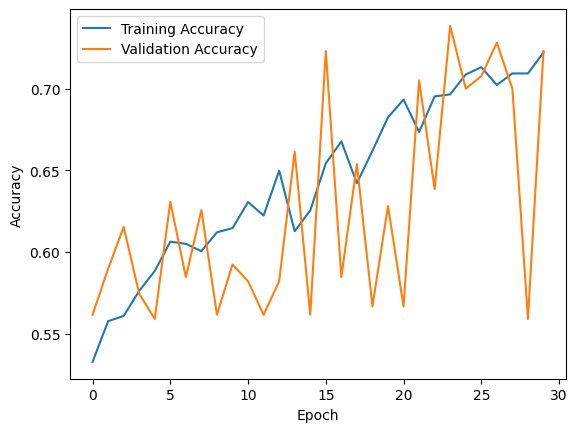

In [25]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

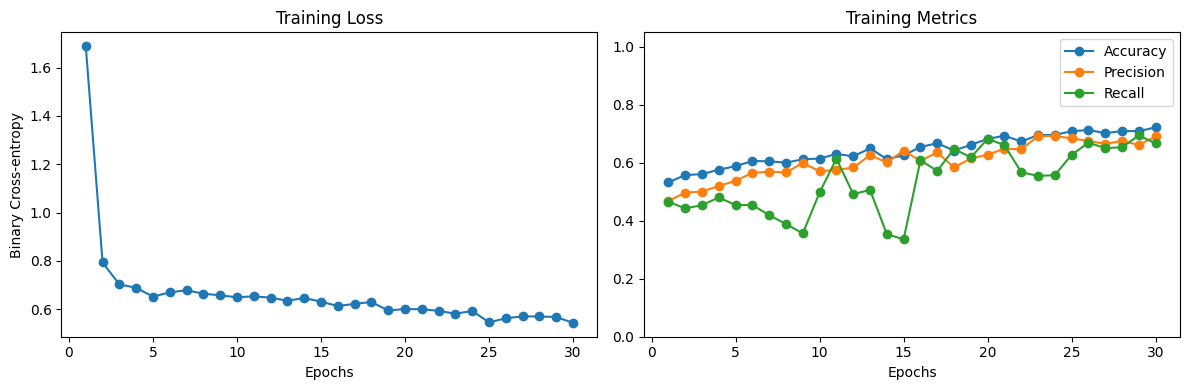

In [26]:
import matplotlib.pyplot as plt

epoch_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_range, history.history['loss'], marker='o')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-entropy')

plt.subplot(1, 2, 2)
plt.plot(epoch_range, history.history['accuracy'], marker='o', label='Accuracy')
plt.plot(epoch_range, history.history['precision'], marker='o', label='Precision')
plt.plot(epoch_range, history.history['recall'], marker='o', label='Recall')
plt.title('Training Metrics')
plt.xlabel('Epochs')
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.show()